# TP 1: From raw text to a first bigram model

In this TP I build a first language model. It reads one character and predicts the next one from a table of scores. It is the first piece of the mini-Transformer I build over four TPs, so I want to understand every tensor shape here.

The diagram follows one example through the data preparation, the model and its loss, then the two loops I will run, training and generation.

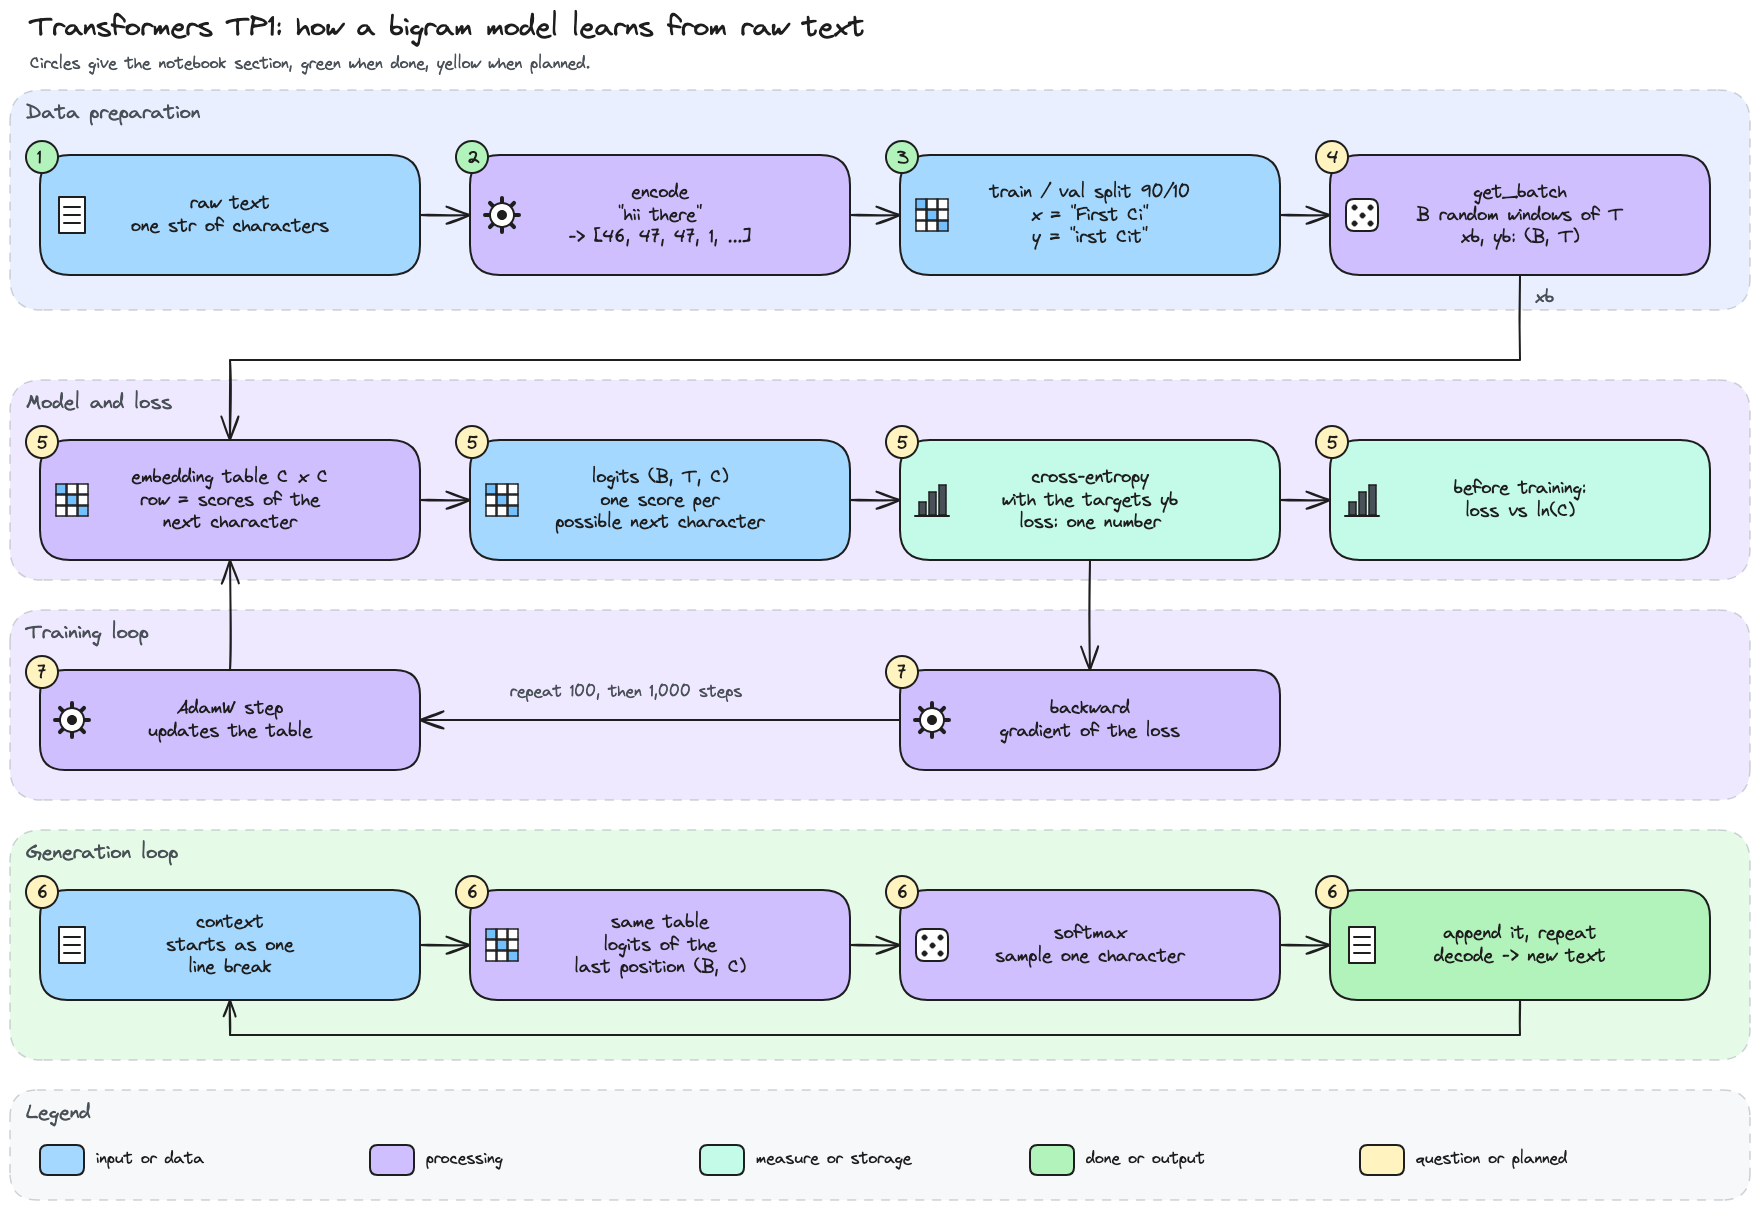

In [1]:
# Workflow diagram: one example through data, model, loss and both loops (diagrams/transformers/).
from IPython.display import Image, display

display(Image(filename='diagrams/transformers/tp1_workflow.png', width=900))

## 0. My problem and what I carry over

I want to predict the next character of Tiny Shakespeare from the characters before it. I already worked on this corpus in my NLP TPs, so I start from what I learnt there. The diagram links each lesson to what it changes here.

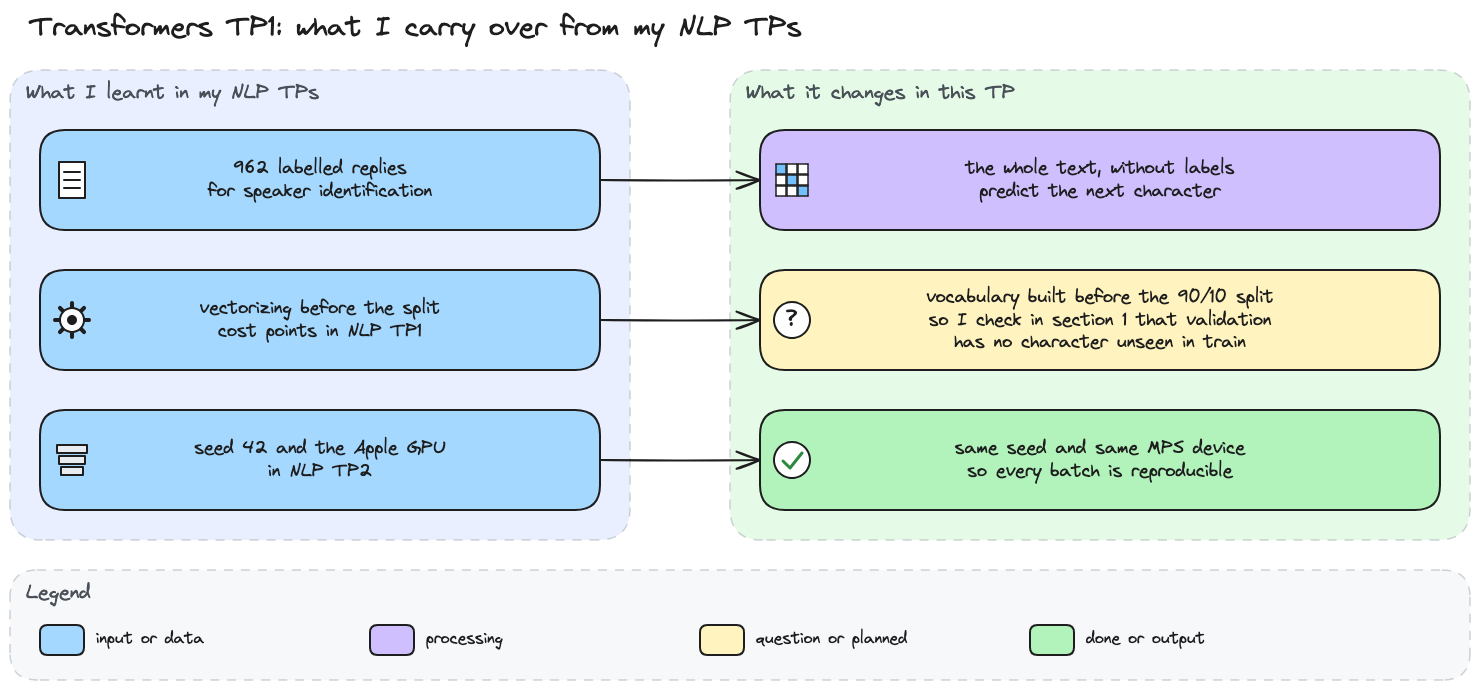

In [2]:
# What I carry over from my NLP TPs (source in diagrams/transformers/).
display(Image(filename='diagrams/transformers/tp1_carry_over.png', width=900))

Before I start, I write down what I expect, so I can check it later.

> *My hypotheses:*
>
> - The corpus has fewer than 100 distinct characters, since it is English text with some punctuation. Sections 1 and 2 check it.
> - Before training, the loss is close to ln(C), where C is the number of distinct characters, because random weights give an almost uniform distribution. I test it in section 5.
> - With a learning rate of 1e-3 (the scale of each weight update), 100 steps barely lower the loss and 1,000 steps lower it clearly. Section 7 compares both.
> - After training, samples keep the line breaks and the capitalised speaker names but contain few real words, because the model only sees the previous character. Section 7 tests this too.

### My environment

I use the project's `.venv/bin/python` as kernel and install the dependencies from the terminal.

```sh
uv pip install --python .venv/bin/python -r requirements.txt
```

I use PyTorch because I want to write the forward pass, the loss and the weight update myself. I train on the Apple GPU through MPS (the PyTorch backend for Mac GPUs), and every version is pinned in `requirements.txt`. I fix seed 42 for the random generators, so my batches and samples are the same at every run.

In [3]:
# Environment: versions, hardware, PyTorch device and one seed for random and torch.
import platform
import random
import subprocess
import sys
from importlib.metadata import version

import torch

# Seed fixed once here, so every random draw below is reproducible.
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# Apple GPU through MPS when available, CPU otherwise
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')

# Versions and dependencies
print(f'Python: {platform.python_version()} ({sys.executable})')
for package in ('torch', 'numpy', 'matplotlib', 'ipykernel'):
    print(f'{package}: {version(package)}')

# System and processor
print(f'System: {platform.platform()}, {platform.machine()}')
if sys.platform == 'darwin':
    processor, ram = subprocess.check_output(
        ['sysctl', '-n', 'machdep.cpu.brand_string', 'hw.memsize'], text=True,
    ).splitlines()
    print(f'Processor: {processor}, RAM: {int(ram) / 2**30:g} GiB')

print(f'Device: {device}, seed: {RANDOM_STATE}')

Python: 3.14.7 (/Users/hopy/Documents/ING3_GIA/ING3_IA_GB_S1/NLP/.venv/bin/python)
torch: 2.14.0
numpy: 2.5.3
matplotlib: 3.11.1
ipykernel: 7.3.0
System: macOS-26.5-arm64-arm-64bit-Mach-O, arm64
Processor: Apple M3 Max, RAM: 36 GiB
Device: mps, seed: 42


## 1. Download and inspect the corpus

Before I write any model, I want to see the text exactly as the model will read it. What I find here decides the vocabulary of section 2 and what the model will have to generate. The diagram shows the measures I take and the questions they answer.

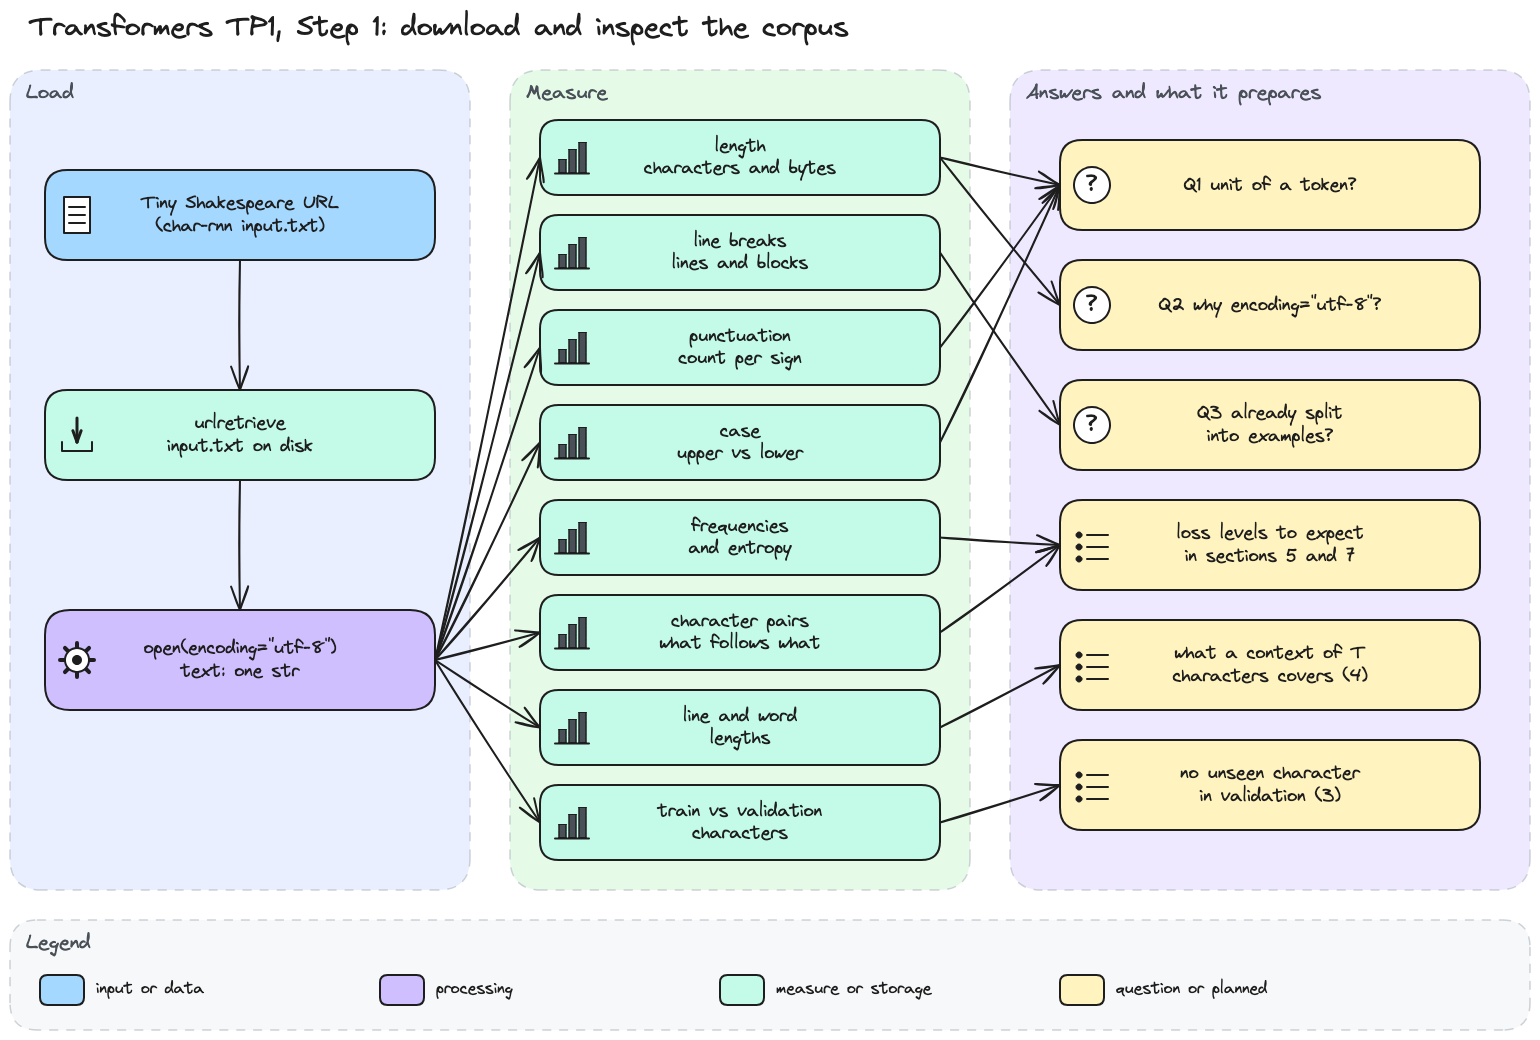

In [4]:
# Step 1 diagram: from the URL to the measures that answer my three questions.
display(Image(filename='diagrams/transformers/tp1_step1.png', width=900))

I download the file once and read it into one string called `text`, because the next TPs reuse this name.

In [5]:
# Download Tiny Shakespeare and read it as one string.
from urllib.request import urlretrieve
import os

url = ("https://raw.githubusercontent.com/karpathy/"
       "char-rnn/master/data/tinyshakespeare/input.txt")
urlretrieve(url, "input.txt")
print(os.path.abspath("input.txt"))

with open("input.txt", "r", encoding="utf-8") as f:
    text = f.read()

print(len(text))

/Users/hopy/Documents/ING3_GIA/ING3_IA_GB_S1/NLP/input.txt
1115394


The whole corpus is one Python string of 1,115,394 characters. Nothing is cut into sentences or examples yet, so everything the model learns will come from this single sequence. I print its beginning to see how it is organised.

In [6]:
# The first 1,000 characters, exactly as the model will read them.
print(text[:1000])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes: for the gods know I
speak this in hunger for bread, not in thirst for revenge.



The text is a play script. A speaker name sits alone on a line and ends with a colon, the reply follows on the next lines, and an empty line closes the block. Punctuation and capitals stay as written, as in `Resolved. resolved.` or `We know't, we know't.`, so the model will have to produce them too.

I opened the file with `encoding="utf-8"`, and I want to know whether this choice changes anything for this file.

In [7]:
# Does the encoding matter here? Compare characters with bytes and look for non-ASCII characters.
import locale

print(f'Characters: {len(text):,}, bytes on disk: {os.path.getsize("input.txt"):,}')
print(f'Non-ASCII characters: {sum(not char.isascii() for char in text)}')
print(f'Default encoding of open() on this machine: {locale.getpreferredencoding(False)}')

Characters: 1,115,394, bytes on disk: 1,115,394
Non-ASCII characters: 0
Default encoding of open() on this machine: UTF-8


The file has as many bytes as characters and no non-ASCII character, so it is plain ASCII and any common encoding decodes it the same way. Why name UTF-8 then? Without it, `open` falls back on the default encoding of the machine. That default is UTF-8 on mine, but naming it makes the notebook read the file the same way on any machine.

The empty lines I saw suggest blocks. I check whether the file is already split into examples.

In [8]:
# Is the text already cut into examples? Count lines, blocks and blocks opened by a speaker name.
import re

line_breaks = text.count('\n')
blocks = text.split('\n\n')
first_lines = [block.split('\n', 1)[0] for block in blocks]
headers = [line for line in first_lines if re.fullmatch(r"[A-Z][A-Za-z' ]*:", line)]  # "Name:"

print(f'Line breaks: {line_breaks:,}')
print(f'Blocks separated by an empty line: {len(blocks):,}')
print(f'Blocks opened by a speaker name alone on its line: {len(headers):,}')

Line breaks: 40,000
Blocks separated by an empty line: 7,222
Blocks opened by a speaker name alone on its line: 7,217


The 40,000 line breaks form the lines, and empty lines cut the text into 7,222 blocks. 7,217 of them open with a speaker name, so the file is laid out for a human reader as a script. Is it split into examples? No. A block has no input and no target, and the model does not see blocks at all. I will build the examples myself in section 3, where each position gives a context and the next character becomes its target.

Next I want to know what the model will have to predict. I group the characters into categories, because each distinct character will become one token.

In [9]:
# Tools: a percentage helper, character category and display, and a bar chart with values.
import string

import matplotlib.pyplot as plt


def percentage(part: int, total: int) -> float:
    """Share of part in total, in percent, rounded to two decimals."""
    return round(100 * part / total, 2)


def character_category(char: str) -> str:
    """Category of one character: line break, space, letter case, digit or punctuation."""
    if char == '\n':
        return 'line break'
    if char == ' ':
        return 'space'
    if char.islower():
        return 'lowercase letter'
    if char.isupper():
        return 'uppercase letter'
    if char.isdigit():
        return 'digit'
    return 'punctuation' if char in string.punctuation else 'other'


def shown(char: str) -> str:
    """Printable form of a character: the line break as \\n and the space as ␣."""
    return {'\n': '\\n', ' ': '␣'}.get(char, char)


def tick(char: str) -> str:
    """Label of a character on a chart, with "$" escaped so it is not read as a formula."""
    return shown(char).replace('$', r'\$')


def bar_chart(labels: list[str], values: list[int], notes: list[str], title: str) -> None:
    """Horizontal bar chart with a note written at the end of each bar."""
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(labels) + 1))
    bars = ax.barh(labels, values, color='#74c0fc')
    ax.bar_label(bars, labels=notes, padding=4)
    ax.set_xlim(0, max(values) * 1.7)
    ax.xaxis.set_major_formatter('{x:,.0f}')
    ax.set_xlabel('occurrences in the text')
    ax.set_title(title)
    ax.spines[['top', 'right']].set_visible(False)
    plt.show()

Distinct characters: 65


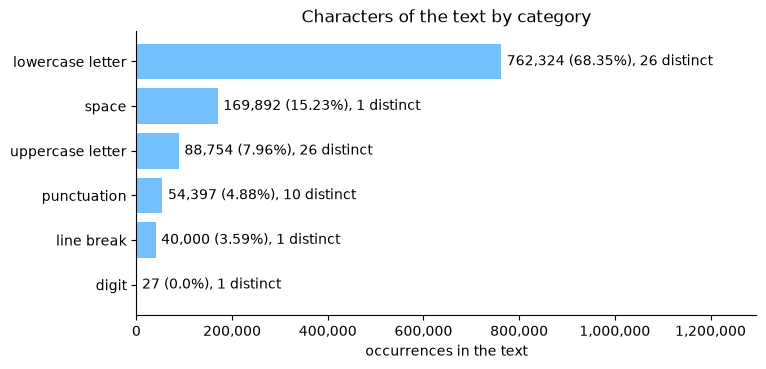

In [10]:
# What kind of characters will the model have to predict?
from collections import Counter

counts = Counter(text)
occurrences, distinct = Counter(), Counter()
for char, n in counts.items():
    occurrences[character_category(char)] += n
    distinct[character_category(char)] += 1

print(f'Distinct characters: {len(counts)}')
categories = sorted(occurrences, key=occurrences.get)
bar_chart(categories, [occurrences[c] for c in categories],
          [f'{occurrences[c]:,} ({percentage(occurrences[c], len(text))}%), '
           f'{distinct[c]} distinct' for c in categories],
          'Characters of the text by category')

What is a token here? One character. The text uses 65 distinct characters, so my vocabulary will have 65 tokens, and my hypothesis of fewer than 100 distinct characters holds for now. Lowercase letters make 68.35% of the text and spaces 15.23%, so most predictions will be a letter or a space. The 26 letters appear in both cases, which means each letter takes two tokens.

Punctuation is only 4.88% of the text, but it has 10 different signs. I look at them one by one.

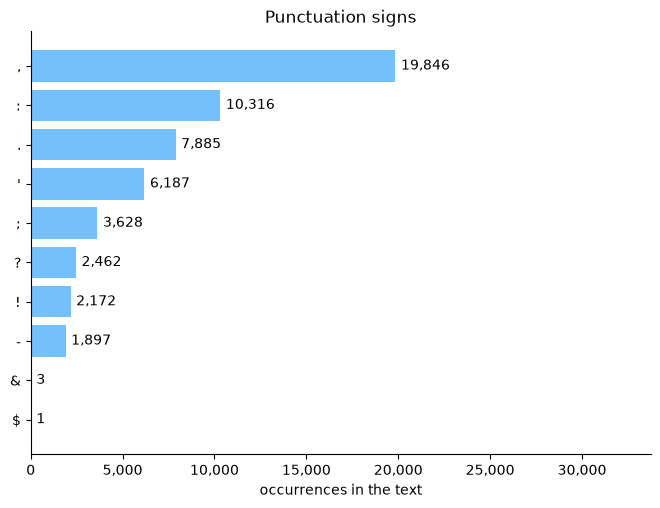

In [11]:
# Which punctuation signs appear, and how often?
signs = sorted((c for c in counts if character_category(c) == 'punctuation'), key=counts.get)
bar_chart([tick(sign) for sign in signs], [counts[sign] for sign in signs],
          [f'{counts[sign]:,}' for sign in signs], 'Punctuation signs')

The comma leads with 19,846 occurrences. The colon comes second with 10,316, and 7,217 of them close a speaker name, so the colon is mostly layout. `&` appears 3 times and `$` once, so the model will almost never see them during training.

The speaker names also seemed to use many capitals. I check how many capitals come from them.

In [12]:
# Where do the capitals come from? Count the capitals that belong to speaker names.
capitals = sum(char.isupper() for char in text)
capitals_in_names = sum(char.isupper() for header in headers for char in header)

print(f'Capitals: {capitals:,}, in speaker names: {capitals_in_names:,} '
      f'({percentage(capitals_in_names, capitals)}%)')
print(f'Speaker names: {len(headers):,}')

Capitals: 88,754, in speaker names: 54,795 (61.74%)
Speaker names: 7,217


61.74% of the capitals are in speaker names. With 54,795 capitals over 7,217 names, a name has about 7.6 capitals, so most names are written in full capitals, unlike `First Citizen` at the top of the file. Case therefore carries part of the script layout, and a good model should learn to write names in capitals after an empty line.

So far I counted characters by kind. A model that ignores the context can only learn how often each character appears, so I look at these frequencies and at what a guess based on them costs.

Uniform guess, ln(65): 4.17 nats
Guess by frequency, entropy of the shares: 3.31 nats


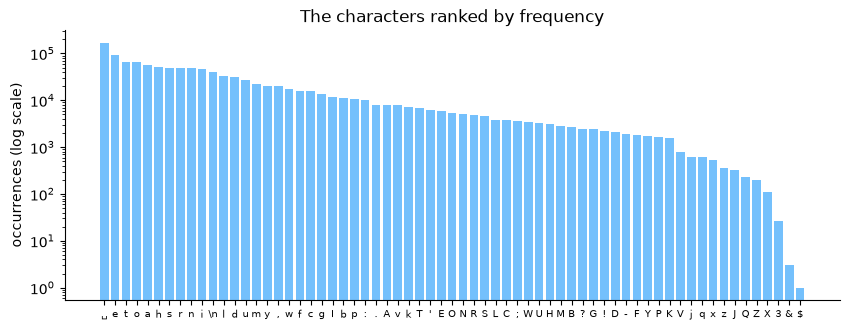

In [13]:
# How often does each character appear, and what does a guess without context cost?
import math

ranked = counts.most_common()
shares = [n / len(text) for _, n in ranked]
entropy = -sum(p * math.log(p) for p in shares)
print(f'Uniform guess, ln({len(counts)}): {math.log(len(counts)):.2f} nats')
print(f'Guess by frequency, entropy of the shares: {entropy:.2f} nats')

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(range(len(ranked)), [n for _, n in ranked], color='#74c0fc')
ax.set_yscale('log')
ax.set_xticks(range(len(ranked)), [tick(char) for char, _ in ranked], fontsize=7)
ax.set_ylabel('occurrences (log scale)')
ax.set_title('The characters ranked by frequency')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The chart falls from the space, the most frequent character, down to `$`, seen once. The tail holds rare letters and signs such as `q`, `Z`, `&` and `$`, so the model will get very few examples of them.

Loss is counted in nats, the natural-log unit that PyTorch's cross-entropy uses. A uniform guess over the 65 characters costs 4.17 nats per character. A guess that only uses these frequencies costs 3.31 nats, so a model that learns nothing about context should still get down to about 3.31. I expect a loss near 4.17 before training, because random weights are close to a uniform guess.

A bigram model also sees the previous character. I count which character follows which, to see what this extra information is worth.

In [14]:
# Which character follows which? Count every pair of neighbours, then normalise each row.
import numpy as np

alphabet = sorted(counts)
index = {char: i for i, char in enumerate(alphabet)}
pair_counts = np.zeros((len(alphabet), len(alphabet)))
for (current, following), n in Counter(zip(text, text[1:])).items():
    pair_counts[index[current], index[following]] = n
next_probs = pair_counts / pair_counts.sum(axis=1, keepdims=True)

# Best loss of a bigram table: the mean of -ln P(next | current) over every pair of the text
seen = pair_counts > 0
bigram_loss = -(pair_counts[seen] * np.log(next_probs[seen])).sum() / pair_counts.sum()
print(f'Pairs that occur: {seen.sum():,} of {len(alphabet) ** 2:,}')
print(f'Best loss of a bigram table on this text: {bigram_loss:.2f} nats')
for char in ('\n', ':', 'q'):
    row = next_probs[index[char]]
    top = [j for j in np.argsort(row)[::-1][:3] if row[j] > 0]
    followers = ', '.join(f'"{shown(alphabet[j])}" {100 * row[j]:.1f}%' for j in top)
    print(f'After "{shown(char)}": {followers}')

Pairs that occur: 1,403 of 4,225
Best loss of a bigram table on this text: 2.45 nats
After "\n": "\n" 18.1%, "T" 10.4%, "A" 9.6%
After ":": "\n" 84.9%, "␣" 14.7%, "'" 0.2%
After "q": "u" 100.0%


Only 1,403 of the 4,225 possible pairs ever occur, so about two thirds of my future table will describe pairs the text never shows. Some rows are almost certain. After `q` comes `u` every time, and after `:` comes a line break 84.9% of the time, which confirms that the colon mostly ends a speaker name. After a line break, the most likely next character is another line break (18.1%), then `T` and `A`, capitals that start a name or a verse line.

A table that knew these probabilities exactly would reach a loss of 2.45 nats on this text. Since my bigram model only ever sees one previous character, this is about the best it can reach in section 7. I draw the whole table to see its structure.

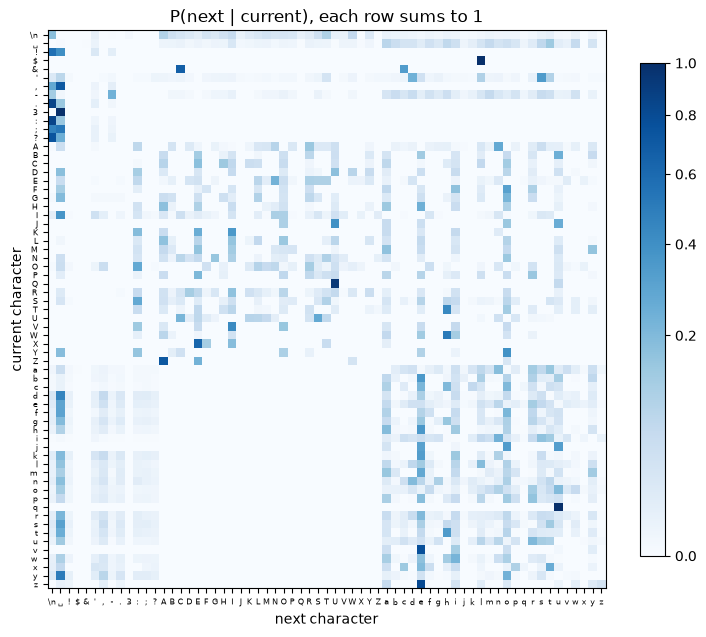

In [15]:
# The same table as a picture: one row per current character, one column per next character.
from matplotlib.colors import PowerNorm

labels = [tick(char) for char in alphabet]
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(next_probs, cmap='Blues', norm=PowerNorm(0.5))  # square root shows faint cells
ax.set_xticks(range(len(alphabet)), labels, fontsize=6)
ax.set_yticks(range(len(alphabet)), labels, fontsize=6)
ax.set_xlabel('next character')
ax.set_ylabel('current character')
ax.set_title('P(next | current), each row sums to 1')
fig.colorbar(image, ax=ax, shrink=0.8)
plt.show()

The picture has clear blocks. Lowercase letters, at the bottom, are mostly followed by lowercase letters, a space or punctuation, and this bottom right block is the densest. Capitals are followed by lowercase letters inside a word, or by other capitals inside a name written in full capitals. The line break row points to capitals and to the line break itself. Most of the table stays white, which matches the 1,403 pairs seen out of 4,225.

The table tells me what follows one character. I now look at how far a longer context reaches, since the next TPs use T characters of context.

Lines: 32,777, median 39 characters, longest 63
Words: 204,062, median 4 characters


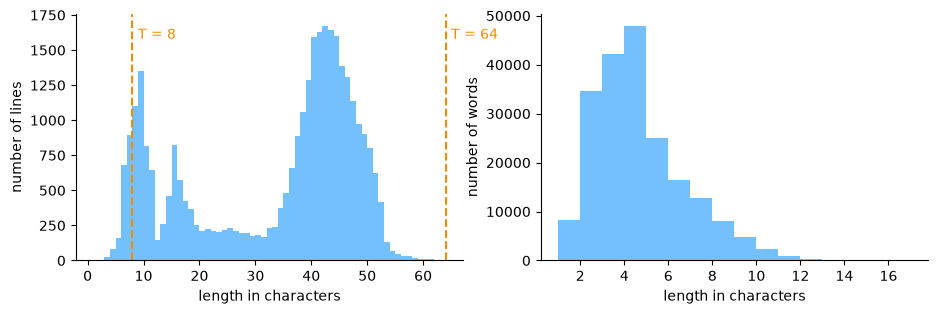

In [16]:
# How long are lines and words? This tells me what a context of T characters can see.
import statistics

line_lengths = [len(line) for line in text.split('\n') if line]
word_lengths = [len(word) for word in re.findall(r"[A-Za-z']+", text)]  # letters, apostrophes
print(f'Lines: {len(line_lengths):,}, median {statistics.median(line_lengths):g} characters, '
      f'longest {max(line_lengths)}')
print(f'Words: {len(word_lengths):,}, median {statistics.median(word_lengths):g} characters')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, lengths, name in ((axes[0], line_lengths, 'lines'), (axes[1], word_lengths, 'words')):
    ax.hist(lengths, bins=range(1, max(lengths) + 2), color='#74c0fc')
    ax.set_xlabel('length in characters')
    ax.set_ylabel(f'number of {name}')
    ax.spines[['top', 'right']].set_visible(False)
for t in (8, 64):
    axes[0].axvline(t, color='#f08c00', linestyle='--')
    axes[0].text(t + 1, axes[0].get_ylim()[1] * 0.9, f'T = {t}', color='#f08c00')
plt.show()

Line lengths have two peaks. The short peak, around 10 characters, fits the speaker-name lines such as `All:` or `First Citizen:`, and the long peak, around 40 to 45 characters, is the verse. The median line has 39 characters and the longest has 63. Words have a median length of 4 characters.

This gives me a feel for T before section 4. With T = 8 the context covers about two words, less than a verse line. With T = 64 it is longer than any line of the text, so the context always reaches back across a line break. My bigram model only uses the last character anyway, so T will matter more for the attention of TP2 than for this table.

Last, the vocabulary is built on the whole text before the 90/10 split of section 3. I check that the last 10% does not bring characters the first 90% never shows.

Characters only in validation: 0 []
Characters only in train: 4 ['$', '&', '3', 'X']
Largest rises in validation: O x1.82, Z x2.07, P x3.31
Largest drops in validation: Q x0.04, J x0.23, Y x0.38


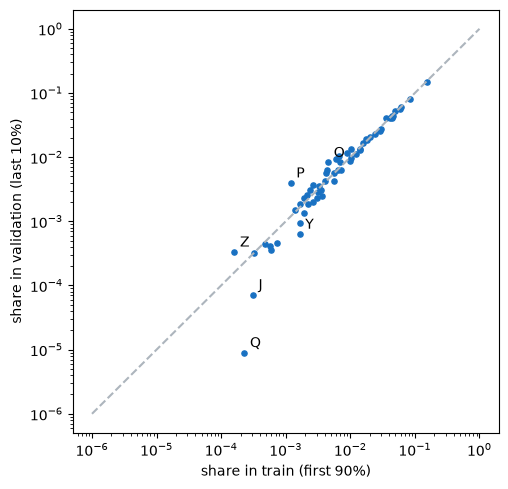

In [17]:
# Does the last 10% of the text, my future validation set, use the same characters as the rest?
split_at = int(0.9 * len(text))
train_counts, val_counts = Counter(text[:split_at]), Counter(text[split_at:])
only_val = sorted(set(val_counts) - set(train_counts))
only_train = [shown(char) for char in sorted(set(train_counts) - set(val_counts))]
print(f'Characters only in validation: {len(only_val)} {only_val}')
print(f'Characters only in train: {len(only_train)} {only_train}')

# Share of each common character in both parts, and the ones whose share moves most
common = [char for char in alphabet if char in val_counts]
train_share = {char: train_counts[char] / split_at for char in common}
val_share = {char: val_counts[char] / (len(text) - split_at) for char in common}
by_ratio = sorted(common, key=lambda char: val_share[char] / train_share[char])
rises = ', '.join(f'{shown(c)} x{val_share[c] / train_share[c]:.2f}' for c in by_ratio[-3:])
drops = ', '.join(f'{shown(c)} x{val_share[c] / train_share[c]:.2f}' for c in by_ratio[:3])
print(f'Largest rises in validation: {rises}')
print(f'Largest drops in validation: {drops}')

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(train_share.values(), val_share.values(), s=14, color='#1971c2')
ax.plot([1e-6, 1], [1e-6, 1], linestyle='--', color='#adb5bd')  # same share in both parts
for char in by_ratio[:3] + by_ratio[-3:]:
    ax.annotate(shown(char), (train_share[char], val_share[char]), xytext=(4, 4),
                textcoords='offset points')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('share in train (first 90%)')
ax.set_ylabel('share in validation (last 10%)')
plt.show()

No character appears only in validation, so building the vocabulary before the split gives validation no unseen token. Four characters, `$`, `&`, `3` and `X`, appear only in train, so the model will never be tested on them.

The points stay close to the diagonal, so both parts use most characters with almost the same shares. The capitals move most. `P` is 3.31 times more frequent in validation and `Z` 2.07 times, while `Q` almost disappears (0.04 times). I suspect the last 10% comes from other scenes with other speaker names. If so, validation is a slightly different text from train, and the validation loss may stay a little above the train loss.

> *My conclusion:*
>
> I keep the text raw, with its case, punctuation and line breaks, because the model has to generate all of them. Section 2 turns the 65 distinct characters into integer ids. I now have three loss levels for sections 5 and 7, 4.17 nats for a uniform guess, 3.31 by frequency alone and 2.45 for a perfect bigram table. I expect my trained table to move from about 4.17 toward 2.45, and never below it. I also expect it to reproduce the script layout, with names in capitals and a line break after the colon.
>
> My answers to the three questions of this step:
>
> 1. A token is one character, and the text has 65 of them.
> 2. Naming UTF-8 makes the decoding independent of the default encoding of the machine, even though this file is plain ASCII.
> 3. The file is not split into examples. It is one string with 7,222 blocks, and section 3 builds the context and target pairs.

## 2. Map characters to integers

PyTorch works on numbers, so each of the 65 characters of section 1 needs an integer id. I build a sorted vocabulary and two maps that must invert each other, then I test them. The diagram shows the way from a string to ids and back, and what I check.

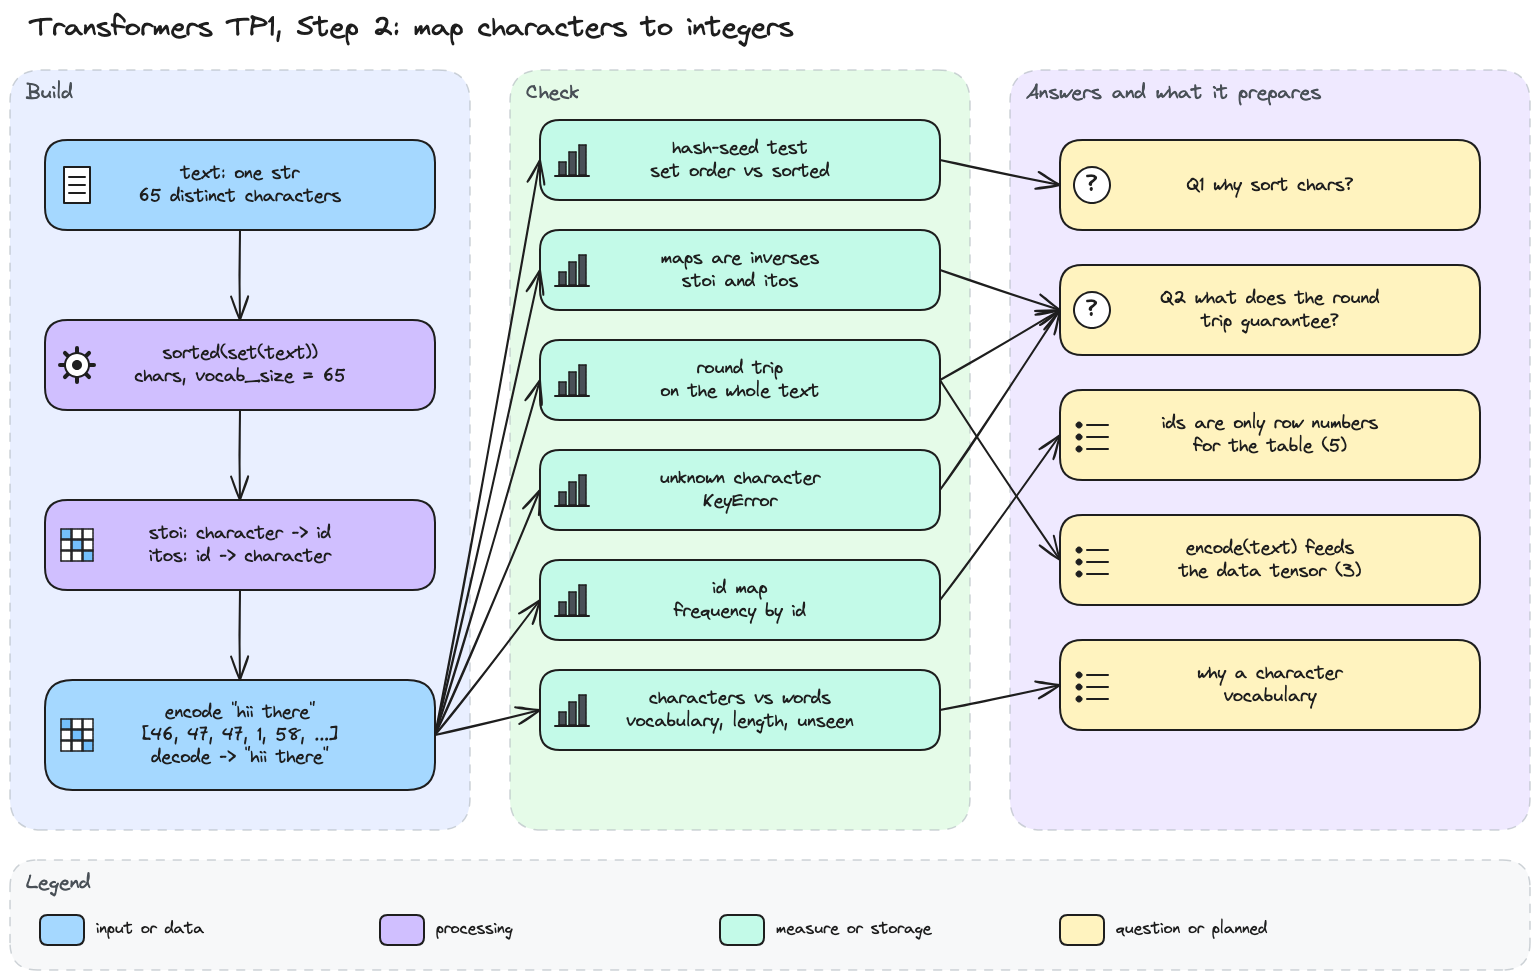

In [18]:
# Step 2 diagram: vocabulary, maps, encode and decode, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp1_step2.png', width=900))

In [19]:
# Vocabulary: the distinct characters of the text, sorted and numbered, then the two maps.
chars = sorted(list(set(text)))
vocab_size = len(chars)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

print(f'vocab_size: {vocab_size}')
print(f'Vocabulary in id order: {"".join(shown(ch) for ch in chars)}')
print(f'itos undoes stoi: {all(itos[stoi[ch]] == ch for ch in chars)}')
print(f'stoi undoes itos: {all(stoi[itos[i]] == i for i in range(vocab_size))}')

vocab_size: 65
Vocabulary in id order: \n␣!$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
itos undoes stoi: True
stoi undoes itos: True


The vocabulary has 65 characters, so my hypothesis of fewer than 100 distinct characters is confirmed. Both checks print True, so every character has exactly one id and every id exactly one character. In id order, the line break comes first, then the space, the signs and the digit, the capitals and the lowercase letters. That is the order of the character codes, because `sorted` compares characters by their code.

A set has no order of its own, though. I want to see what would happen if I numbered the characters straight from the set.

In [20]:
# Why sort? Build the vocabulary in three new Python processes, each with another hash seed.
import os
import subprocess
import sys

SNIPPET = ("text = open('input.txt', encoding='utf-8').read()\n"
           "print('set', repr(''.join(list(set(text)))[:12]),"
           " ' sorted', repr(''.join(sorted(set(text)))[:12]))")

for seed in ('1', '2', '3'):
    child = subprocess.run([sys.executable, '-c', SNIPPET], capture_output=True, text=True,
                           env={**os.environ, 'PYTHONHASHSEED': seed})
    print(f'hash seed {seed}: {child.stdout.strip()}')

hash seed 1: set 'VtM.;k3b$LyR'  sorted "\n !$&',-.3:;"
hash seed 2: set 'hkIJEmO:VG&p'  sorted "\n !$&',-.3:;"
hash seed 3: set 'JayQo:fDk?u!'  sorted "\n !$&',-.3:;"


In each new process the set gives the characters in another order, while the sorted list starts with the same characters every time. Python shuffles the order of a set of strings with a hash seed that changes at each start. Why sort `chars` then? Without sorting, `h` could get id 46 in one run and another id in the next. The rows of the table I train in section 5 would then point to other characters when I reload it, and generated ids would decode into the wrong text.

With a stable numbering, I can now write `encode` and `decode`.

In [21]:
# Encode and decode as two lambdas, tried on a short message.
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: ''.join([itos[i] for i in ids])

message = "hii there"
print(encode(message))
print(decode(encode(message)))

[46, 47, 47, 1, 58, 46, 43, 56, 43]
hii there


`hii there` becomes nine ids, one per character. The two `i` both get 47 and the two `h` both get 46, so a character always keeps its id, and the space is 1. Decoding gives the message back.

I check whether this still holds on the whole text, and what happens with a character the text never uses.

In [22]:
# Does the round trip hold on the whole text? And what happens with a character outside it?
print(f'decode(encode(text)) == text: {decode(encode(text)) == text}')
print(f'Ids produced for the whole text: {len(encode(text)):,}')

try:
    encode("café")
except KeyError as error:
    print(f'encode("café") raises KeyError: {error}')

decode(encode(text)) == text: True
Ids produced for the whole text: 1,115,394
encode("café") raises KeyError: 'é'


The round trip gives back the whole text exactly, from 1,115,394 ids. What does the test guarantee? That encoding loses nothing on this vocabulary, since each character has one id and each id one character. So any ids the model produces can always be turned back into text. It says nothing about new characters, since `é` raises a KeyError. My vocabulary is closed, which is safe here because section 1 showed that validation has no character missing from train.

The ids look like numbers, so I want to check whether they carry any meaning.

line break: ids 0 to 0
space: ids 1 to 1
punctuation: ids 2 to 12
digit: ids 9 to 9
uppercase letter: ids 13 to 38
lowercase letter: ids 39 to 64
'A' -> 13, 'a' -> 39


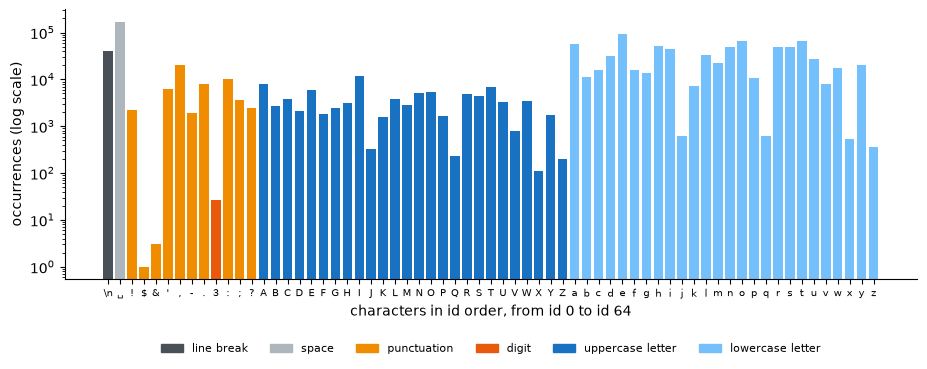

In [23]:
# What does an id say? Frequency of each id, in id order, coloured by the category of its character.
from matplotlib.patches import Patch

CATEGORY_COLOURS = {'line break': '#495057', 'space': '#adb5bd', 'punctuation': '#f08c00',
                    'digit': '#e8590c', 'uppercase letter': '#1971c2',
                    'lowercase letter': '#74c0fc'}

for category in CATEGORY_COLOURS:
    ids = [stoi[ch] for ch in chars if character_category(ch) == category]
    print(f'{category}: ids {min(ids)} to {max(ids)}')
print(f"'A' -> {stoi['A']}, 'a' -> {stoi['a']}")

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(range(vocab_size), [counts[ch] for ch in chars],
       color=[CATEGORY_COLOURS[character_category(ch)] for ch in chars])
ax.set_yscale('log')
ax.set_xticks(range(vocab_size), [tick(ch) for ch in chars], fontsize=7)
ax.set_xlabel('characters in id order, from id 0 to id 64')
ax.set_ylabel('occurrences (log scale)')
legend = [Patch(color=colour, label=name) for name, colour in CATEGORY_COLOURS.items()]
ax.legend(handles=legend, fontsize=8, ncols=6, frameon=False, loc='upper center',
          bbox_to_anchor=(0.5, -0.2))
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Ids follow the character codes. The line break is 0, the space 1, the signs and the digit 2 to 12, the capitals 13 to 38 and the lowercase letters 39 to 64. Along the ids, the frequency jumps up and down, and `A` (13) sits far from `a` (39) although they are the same letter. So an id says nothing about how frequent a character is or how close two characters are. It only numbers a row, and the table of section 5 will have to learn what each row means.

I chose one token per character. I compare it with one token per word, the unit I used in my NLP TPs.

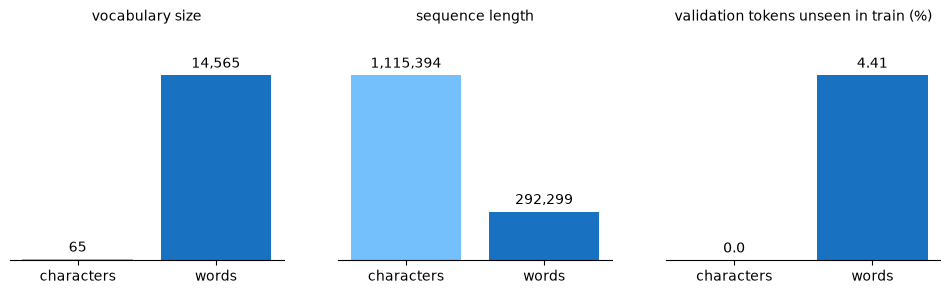

In [24]:
# Characters or words? Compare vocabulary size, sequence length and unseen tokens in validation.
WORD_PATTERN = r"[A-Za-z']+|[^A-Za-z'\s]|\n"  # a word, a single sign or a line break

tokenizers = {'characters': list, 'words': lambda s: re.findall(WORD_PATTERN, s)}
measures = {}
for name, tokenize in tokenizers.items():
    train_tokens, val_tokens = tokenize(text[:split_at]), tokenize(text[split_at:])
    known = set(train_tokens)
    unseen = sum(token not in known for token in val_tokens)
    measures[name] = [len(known | set(val_tokens)), len(train_tokens) + len(val_tokens),
                      percentage(unseen, len(val_tokens))]

titles = ['vocabulary size', 'sequence length', 'validation tokens unseen in train (%)']
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for k, (ax, title) in enumerate(zip(axes, titles)):
    values = [measures[name][k] for name in tokenizers]
    bars = ax.bar(list(tokenizers), values, color=['#74c0fc', '#1971c2'])
    ax.bar_label(bars, labels=[f'{value:,}' for value in values], padding=3)
    ax.set_title(title, fontsize=10)
    ax.set_ylim(0, max(values) * 1.25)
    ax.set_yticks([])
    ax.spines[['top', 'right', 'left']].set_visible(False)
plt.show()

Characters give a vocabulary of 65 tokens against 14,565 for words, and no validation character is unseen. With words, 4.41% of validation tokens never appear in train, so I would need an unknown token as in NLP TP2, and these words would be lost. The price of characters is length. The text becomes 1,115,394 tokens instead of 292,299, about 3.8 times more, so a context of T tokens covers fewer words. A token can also be a piece of a word, which sits between these two choices.

> *My conclusion:*
>
> I now have a closed vocabulary of 65 characters, numbered in sorted order so that the ids stay the same at every run. `encode` turns the text into 1,115,394 ids without losing anything, and section 3 turns them into a tensor. An id is only a row number, so the table of section 5 has to learn what each row means.
>
> My answers to the two questions of this step:
>
> 1. I sort `chars` because a set has no stable order between runs, and a character must keep the same id so that the trained table and the decoding stay valid.
> 2. The round trip guarantees that encoding loses nothing on this vocabulary, since the two maps invert each other. It guarantees nothing for a character outside the vocabulary, which raises a KeyError.

## 3. Build the expected predictions

A model learns from pairs of a context and the character that follows it. I turn the ids into one tensor, split it into train and validation, and cut one block to see which pairs it holds. The diagram shows the path and the checks behind my answers.

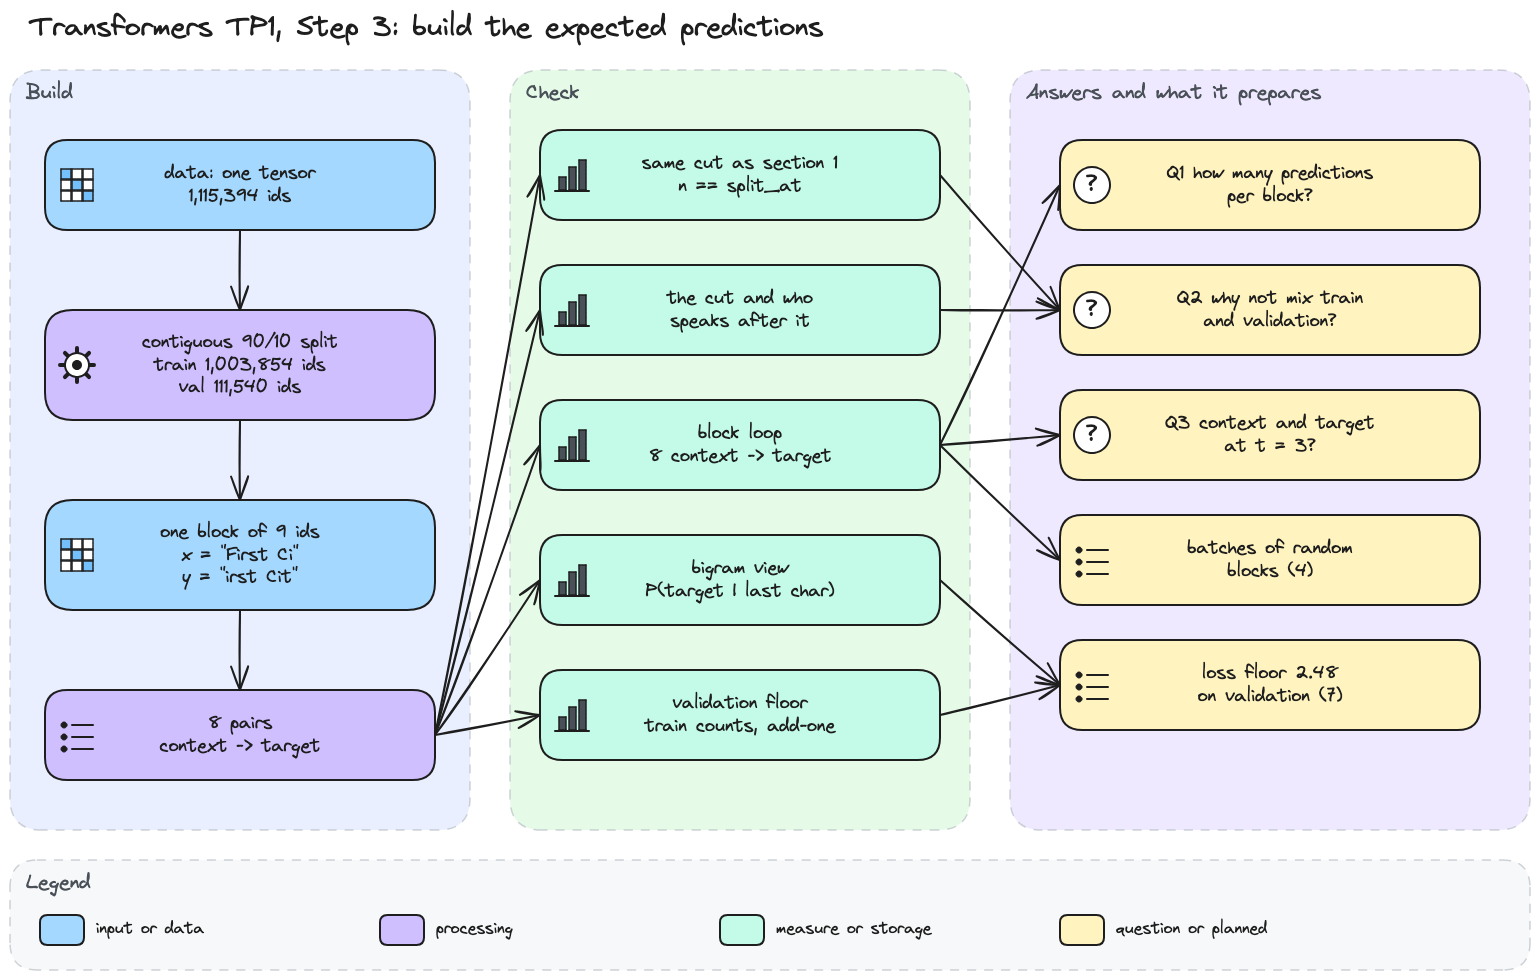

In [25]:
# Step 3 diagram: tensor, split, one block of predictions, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp1_step3.png', width=900))

In [26]:
# The whole text as one tensor of ids, then a 90/10 split by position.
data = torch.tensor(encode(text), dtype=torch.long)

n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]

print(f'data: shape {tuple(data.shape)}, dtype {data.dtype}')
print(f'First ids: {data[:9].tolist()} -> {decode(data[:9].tolist())!r}')
print(f'train_data: {len(train_data):,} ids, val_data: {len(val_data):,} ids')
print(f'Same cut as split_at in section 1: {n == split_at}')

data: shape (1115394,), dtype torch.int64
First ids: [18, 47, 56, 57, 58, 1, 15, 47, 58] -> 'First Cit'
train_data: 1,003,854 ids, val_data: 111,540 ids
Same cut as split_at in section 1: True


The text is now one tensor of 1,115,394 ids, one per character, and its first ids decode back to `First Cit`. I keep the 64-bit integer type, because these ids will index the rows of the table in section 5. The cut gives 1,003,854 ids to train and 111,540 to validation, at the same place as `split_at` in section 1. So the check of section 1 still holds, and validation has no character missing from train.

The split takes the first 90% for train and the last 10% for validation, without shuffling. I want to see where this cut falls and what lies after it.

Before the cut: 'ntleman thus grieved as I?\nBut who comes here'
After the cut:  '?\n\nGREMIO:\nGood morrow, neighbour Baptista.\n\n'
Validation speakers: 36, never speaking in train: 24
Validation blocks they open: 367 of 919


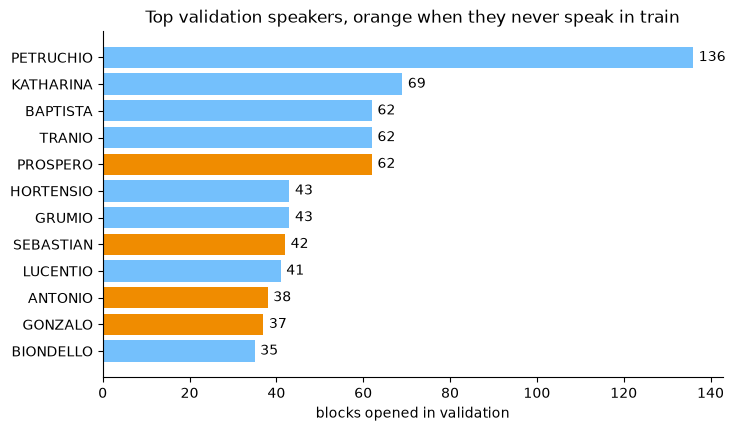

In [27]:
# Where does the cut fall, and who speaks on each side of it?
HEADER = r"(?:\A|\n\n)([A-Z][A-Za-z' ]*):\n"  # a name alone on the first line of a block

print(f'Before the cut: {decode(data[n - 45:n].tolist())!r}')
print(f'After the cut:  {decode(data[n:n + 45].tolist())!r}')

train_names = Counter(re.findall(HEADER, text[:n]))
val_names = Counter(re.findall(HEADER, text[n:]))
new_names = [name for name in val_names if name not in train_names]
print(f'Validation speakers: {len(val_names)}, never speaking in train: {len(new_names)}')
print(f'Validation blocks they open: {sum(val_names[name] for name in new_names)} '
      f'of {sum(val_names.values())}')

top = val_names.most_common(12)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh([name for name, _ in top], [count for _, count in top],
               color=['#f08c00' if name in new_names else '#74c0fc' for name, _ in top])
ax.bar_label(bars, padding=4)
ax.set_xlabel('blocks opened in validation')
ax.set_title('Top validation speakers, orange when they never speak in train')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The cut even falls inside a sentence, between `But who comes here` and its question mark. After it, validation is partly made of other scenes. 24 of its 36 speakers never speak in train, and they open 367 of its 919 blocks. The chart shows two groups. PETRUCHIO, KATHARINA and BAPTISTA already speak in train, while PROSPERO, SEBASTIAN, ANTONIO and GONZALO only appear in validation. PETRUCHIO alone opens 136 blocks and PROSPERO 62, which explains why `P` was more frequent in validation in section 1.

Why not mix train and validation? A window that starts one character later shares 8 of its 9 characters with the previous one. If I mixed windows at random, validation would hold almost the same text as train, and its loss would reward memory. With a contiguous cut, validation measures how the model does on scenes and speakers it never saw.

Now I cut one block of the train set to see the pairs it holds.

In [28]:
# One block of the train set: x is the input, y the same characters shifted by one position.
block_size = 8
x = train_data[:block_size]
y = train_data[1:block_size + 1]

for t in range(block_size):
    context = x[:t + 1]
    target = y[t]
    print(context, "->", target, f"   {decode(context.tolist())!r} -> {itos[target.item()]!r}")

tensor([18]) -> tensor(47)    'F' -> 'i'
tensor([18, 47]) -> tensor(56)    'Fi' -> 'r'
tensor([18, 47, 56]) -> tensor(57)    'Fir' -> 's'
tensor([18, 47, 56, 57]) -> tensor(58)    'Firs' -> 't'
tensor([18, 47, 56, 57, 58]) -> tensor(1)    'First' -> ' '
tensor([18, 47, 56, 57, 58,  1]) -> tensor(15)    'First ' -> 'C'
tensor([18, 47, 56, 57, 58,  1, 15]) -> tensor(47)    'First C' -> 'i'
tensor([18, 47, 56, 57, 58,  1, 15, 47]) -> tensor(58)    'First Ci' -> 't'


How many predictions does this block produce? Eight, one per position, from the 9 characters of `train_data[:9]`. Each target becomes the last character of the next context, so the contexts grow from 1 to 8 characters. For t = 3, the context is `tensor([18, 47, 56, 57])`, which is `Firs`, and the target is `tensor(58)`, which is `t`. Sliding over the whole train set, every position gives one prediction, so about 1,003,853 of them (n minus 1).

My bigram model will only look at the last character of each context. I check what that single character says about each target.

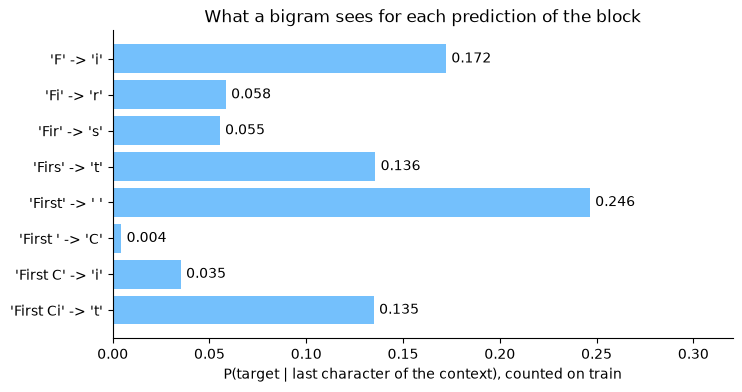

In [29]:
# What does the last character of each context say about its target? Pairs counted on train only.
train_pairs = torch.zeros((vocab_size, vocab_size))
train_pairs.index_put_((train_data[:-1], train_data[1:]), torch.ones(n - 1), accumulate=True)
train_probs = train_pairs / train_pairs.sum(dim=1, keepdim=True)

labels = [f'{decode(x[:t + 1].tolist())!r} -> {itos[y[t].item()]!r}' for t in range(block_size)]
probs = [train_probs[x[t], y[t]].item() for t in range(block_size)]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(labels[::-1], probs[::-1], color='#74c0fc')
ax.bar_label(bars, labels=[f'{p:.3f}' for p in probs[::-1]], padding=4)
ax.set_xlim(0, max(probs) * 1.3)
ax.set_xlabel('P(target | last character of the context), counted on train')
ax.set_title('What a bigram sees for each prediction of the block')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

For a bigram, `First ` followed by `C` is the hardest prediction with 0.004, since many characters can follow a space. `First` followed by a space is the easiest with 0.246. After `C`, the bigram gives `i` only 0.035, although anyone reading `First C` at the top of the play guesses `Citizen`. One character cannot see the word it belongs to. Longer contexts, which the attention of TP2 will use, should fix exactly this kind of prediction.

The next question is how low such a table can go on text it never saw.

In [30]:
# How low can a bigram table go on validation? I score both parts with the train counts.
val_seen = train_pairs[val_data[:-1], val_data[1:]] > 0
unseen = int((~val_seen).sum())
print(f'Validation pairs never seen in train: {unseen} of {len(val_data) - 1:,} '
      f'({percentage(unseen, len(val_data) - 1)}%)')

smoothed = (train_pairs + 1) / (train_pairs + 1).sum(dim=1, keepdim=True)  # add-one smoothing
train_loss = -torch.log(train_probs[train_data[:-1], train_data[1:]]).mean().item()
val_loss = -torch.log(smoothed[val_data[:-1], val_data[1:]]).mean().item()
print(f'Table counted on train, loss on train: {train_loss:.2f} nats')
print(f'Same table with add-one smoothing, loss on validation: {val_loss:.2f} nats')

Validation pairs never seen in train: 187 of 111,539 (0.17%)
Table counted on train, loss on train: 2.45 nats
Same table with add-one smoothing, loss on validation: 2.48 nats


Only 187 of the 111,539 validation pairs never appear in train, 0.17%. Add-one smoothing adds one to every count, so these pairs keep a small probability instead of an infinite loss. The table counted on train reaches 2.45 nats on train and 2.48 on validation. So even with perfect counts, a bigram model should not go below about 2.48 on validation, which is my realistic target for section 7. The gap of 0.03 is small, so the new scenes change which characters follow which only a little.

> *My conclusion:*
>
> The text is one tensor of 1,115,394 ids, cut into 1,003,854 for train and 111,540 for validation. The cut is contiguous, so validation also tests scenes and speakers the model never saw. Every position gives one prediction, and a block of 9 characters gives 8 of them, with contexts from 1 to 8 characters. A bigram only sees the last character, so its loss should not go below 2.45 on train and 2.48 on validation. Section 4 stacks many random blocks into one batch.
>
> My answers to the three questions of this step:
>
> 1. A block of `block_size + 1` = 9 characters produces 8 predictions, one per position.
> 2. Windows one character apart share 8 of their 9 characters, so mixing them would put almost the same text in both sets. The contiguous cut keeps validation on unseen text.
> 3. For t = 3, the context is `[18, 47, 56, 57]` (`Firs`) and the target is 58 (`t`).

## 4. Sample a mini-batch

I will stack B independent sequences of length T into one batch, so the model computes all their predictions in parallel. A median line has 39 characters (section 1), so I want to see what T = 8 and T = 64 change in the shapes.

## 5. Produce logits with a table

My first model is a table where each character picks one row of scores for the next character. I will check the `(B, T, C)` shape of the logits and compare the loss before training with ln(C), as I expect a near-uniform guess at that point.

## 6. Generate before training

I will generate text from random weights by sampling one character at a time from the last position. This sample is my reference for the comparison after training.

## 7. Train, then compare

I will train the table with AdamW and compare the loss and the samples after 100 and 1,000 steps. I will read the loss against the levels of section 1, 3.31 nats by frequency and 2.45 for a perfect bigram table. On validation, my reference is the 2.48 that a table counted on train reaches (section 3). This is where I test what 100 and 1,000 steps change and what a bigram model can learn.

## Summary

I will gather what I measured at each step and what it taught me about how a language model learns from raw text.